# Pré-processamento dos dados

Classificação de frutas e vegetais **saudáveis x podres** com CNN.
Dataset: [Fruit and Vegetable Disease (Healthy vs Rotten)](https://www.kaggle.com/datasets/muhammad0subhan/fruit-and-vegetable-disease-healthy-vs-rotten),
29.277 imagens em 28 classes (14 frutas/vegetais × saudável/podre).

Este notebook **mostra** o pré-processamento; o código fica em `src/` e é o mesmo que todos os modelos importam:

| Arquivo | O que faz |
|---|---|
| `src/data_loader.py` | download, divisão treino/val/teste, leitura, resize e cache (`tf.data.Dataset`) |
| `src/duplicates.py` | detecção de imagens duplicadas e correção do vazamento entre splits |
| `src/preprocessing.py` | normalização, *data augmentation* e pesos das classes |

**Etapas:**
1. Carregamento e padronização (RGB, 224×224)
2. Divisão estratificada e distribuição das classes
3. Duplicatas e vazamento de dados
4. Normalização
5. Aumento de dados (*data augmentation*)
6. Desbalanceamento: pesos das classes

In [1]:
import sys, warnings
from collections import Counter
from pathlib import Path

# Encontra a raiz do projeto (pasta que contém src/) para conseguir importar o código
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display

from src import config
from src.data_loader import load_datasets, read_splits, download_dataset, SPLITS
from src import duplicates as dup
from src.preprocessing import build_augmentation, build_normalization, compute_class_weights

%matplotlib inline
print("Raiz do projeto:", ROOT)

I0000 00:00:1795483059.764385    9598 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1795483059.801801    9598 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


Raiz do projeto: /home/tais/Documents/cnn-ciencia-de-dados


I0000 00:00:1795483060.923306    9598 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


## 1. Carregamento e padronização

O `load_datasets()` devolve três `tf.data.Dataset` (treino, validação e teste). Para cada imagem ele:

- **decodifica em RGB (3 canais)**: o dataset mistura JPEG, PNG e imagens com paleta;
- **redimensiona para 224×224**, a entrada padrão das principais arquiteturas pré-treinadas;
- **descarta arquivos corrompidos** em vez de interromper o treino;
- guarda as imagens já redimensionadas num **cache em disco** (`data/cache/`), acelerando as épocas seguintes
  (aqui usamos `cache=None` só para a demonstração);
- embaralha o treino a cada época e agrupa em *batches* com *prefetch*.

A saída são imagens `float32` em **[0, 255]** e rótulos inteiros (`sparse_categorical_crossentropy`).

In [2]:
train_ds, val_ds, test_ds, class_names = load_datasets(cache=None)

images, labels = next(iter(train_ds))
print("Formato do batch:", images.shape, "| tipo:", images.dtype)
print("Faixa dos pixels:", float(images.numpy().min()), "a", float(images.numpy().max()))
print("Rótulos (inteiros):", labels.numpy()[:10])

Path to dataset files: /home/tais/.cache/kagglehub/datasets/muhammad0subhan/fruit-and-vegetable-disease-healthy-vs-rotten/versions/1


E0000 00:00:1795483063.652218    9598 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


train:  20491 imagens
val  :   4393 imagens
test :   4393 imagens
28 classes | cache=None


W0000 00:00:1795483064.392930    9676 png_io.cc:96] PNG warning: iCCP: known incorrect sRGB profile
W0000 00:00:1795483069.423679    9673 png_io.cc:96] PNG warning: iCCP: known incorrect sRGB profile
I0000 00:00:1795483073.817258    9688 shuffle_dataset_op.cc:453] ShuffleDatasetV3:3: Filling up shuffle buffer (this may take a while): 17783 of 20491
W0000 00:00:1795483073.824385    9684 png_io.cc:96] PNG warning: iCCP: known incorrect sRGB profile
I0000 00:00:1795483076.217802    9688 shuffle_dataset_op.cc:483] Shuffle buffer filled.


Formato do batch: (32, 224, 224, 3) | tipo: <dtype: 'float32'>
Faixa dos pixels: 0.0 a 255.0
Rótulos (inteiros): [ 0  1 27  5  3 18 17 13 25 25]


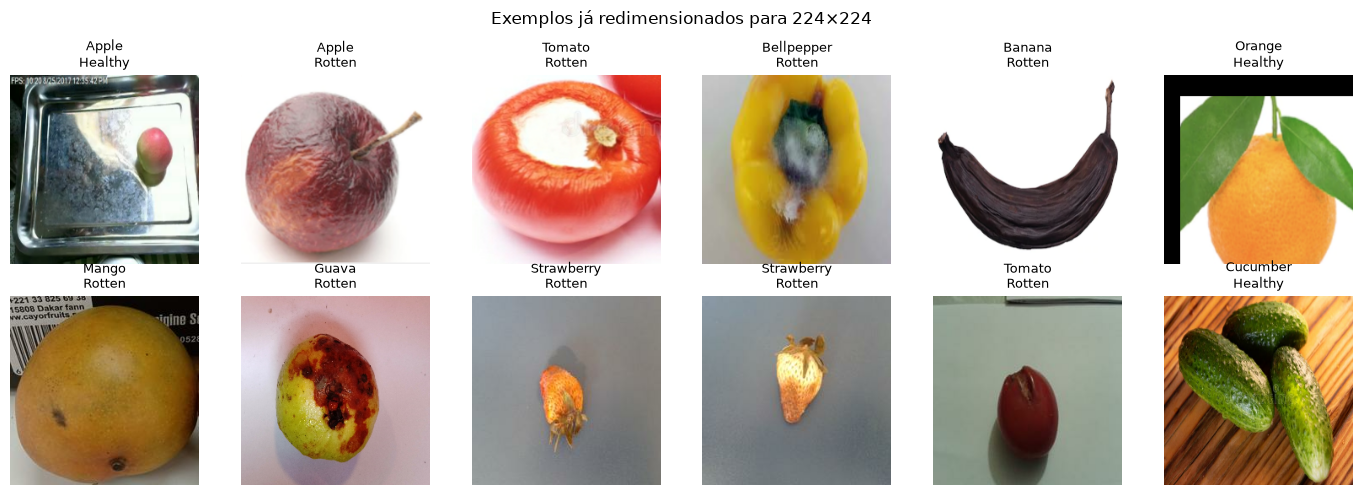

In [3]:
fig, axes = plt.subplots(2, 6, figsize=(14, 5))
for ax, img, y in zip(axes.flat, images, labels):
    ax.imshow(img.numpy().astype("uint8"))
    ax.set_title(class_names[int(y)].replace("__", "\n"), fontsize=9)
    ax.axis("off")
fig.suptitle("Exemplos já redimensionados para 224×224")
plt.tight_layout(); plt.show()

## 2. Divisão estratificada e distribuição das classes

A divisão é **70% treino / 15% validação / 15% teste**, **estratificada por classe** (cada split mantém a
proporção de cada classe) e com semente fixa (42). Ela fica salva em `data/splits.csv`, versionado no git,
para que **todos os experimentos usem exatamente as mesmas imagens**.

train:  20491 imagens (70.0%)
val  :   4393 imagens (15.0%)
test :   4393 imagens (15.0%)


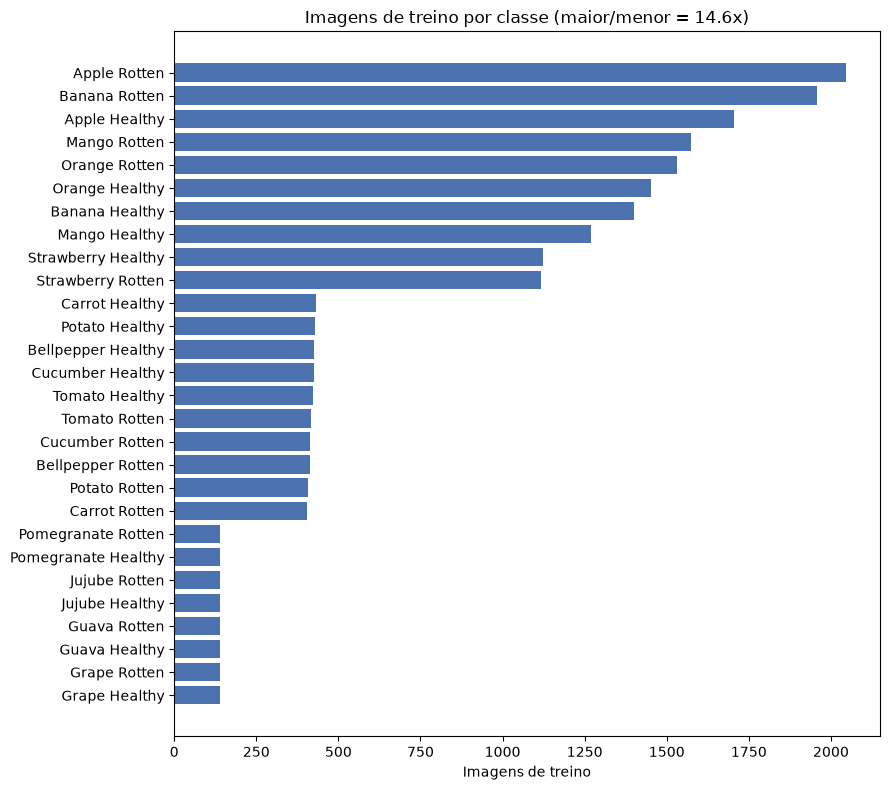

In [4]:
rows = read_splits()
por_split = Counter(r["split"] for r in rows)
for s in SPLITS:
    print(f"{s:5s}: {por_split[s]:6d} imagens ({por_split[s] / len(rows):.1%})")

treino = Counter(r["class_name"] for r in rows if r["split"] == "train")
ordem = sorted(class_names, key=treino.__getitem__)
fig, ax = plt.subplots(figsize=(9, 8))
ax.barh([c.replace("__", " ") for c in ordem], [treino[c] for c in ordem], color="#4C72B0")
ax.set_xlabel("Imagens de treino")
ax.set_title(f"Imagens de treino por classe (maior/menor = {max(treino.values()) / min(treino.values()):.1f}x)")
plt.tight_layout(); plt.show()

As classes são bastante **desbalanceadas**: Grape, Guava, Jujube e Pomegranate têm só 140 imagens de
treino cada, enquanto as maiores passam de 2.000. Isso é tratado na seção 6.

## 3. Duplicatas e vazamento de dados

O dataset tem muitas imagens **repetidas ou quase idênticas**: o mesmo objeto fotografado em sequência
(como frames de vídeo) e cópias renomeadas vindas de fontes diferentes. Com a divisão aleatória, cópias
da mesma foto caem no treino **e** no teste. O modelo seria avaliado em imagens que, na prática, já viu,
e as métricas ficariam infladas.

**Detecção** (`src/duplicates.py`):
- **Exatas**: arquivos idênticos (hash MD5).
- **Quase idênticas**: hash perceptual (*dHash*, 64 bits) com até 4 bits de diferença **e** diferença média
  de cor ≤ 6 (escala 0–255) numa miniatura 16×16. Só o hash não basta: ele junta frutas diferentes
  fotografadas sobre o mesmo fundo. Os limites foram calibrados olhando pares do próprio dataset.

**Correção**: cada grupo de duplicatas é colocado inteiro num único split (prioridade treino > validação > teste).
O resto da divisão não muda.

In [5]:
root = download_dataset()
groups, cross_class = dup.find_duplicates(root, rows)
changes = dup.plan_fix(rows, groups)
dup.print_summary(rows, groups, cross_class, changes)

Path to dataset files: /home/tais/.cache/kagglehub/datasets/muhammad0subhan/fruit-and-vegetable-disease-healthy-vs-rotten/versions/1

29277 imagens analisadas
Grupos de duplicatas (mesma classe): 3358 (1583 exatos, 1775 quase iguais), 7642 imagens
Grupos espalhados em mais de um split (vazamento): 1648
Imagens que precisam mudar de split: 1868
  test  -> train: 853
  test  -> val  : 134
  val   -> train: 881

Imagens por split (antes -> depois):
  train:  20491 ->  22225
  val  :   4393 ->   3646
  test :   4393 ->   3406

Aviso: 10 pares de imagens iguais em CLASSES diferentes (possível erro de rótulo; não alterados). Veja duplicates_entre_classes.csv


Prévia salva em /home/tais/Documents/cnn-ciencia-de-dados/duplicates_preview.png


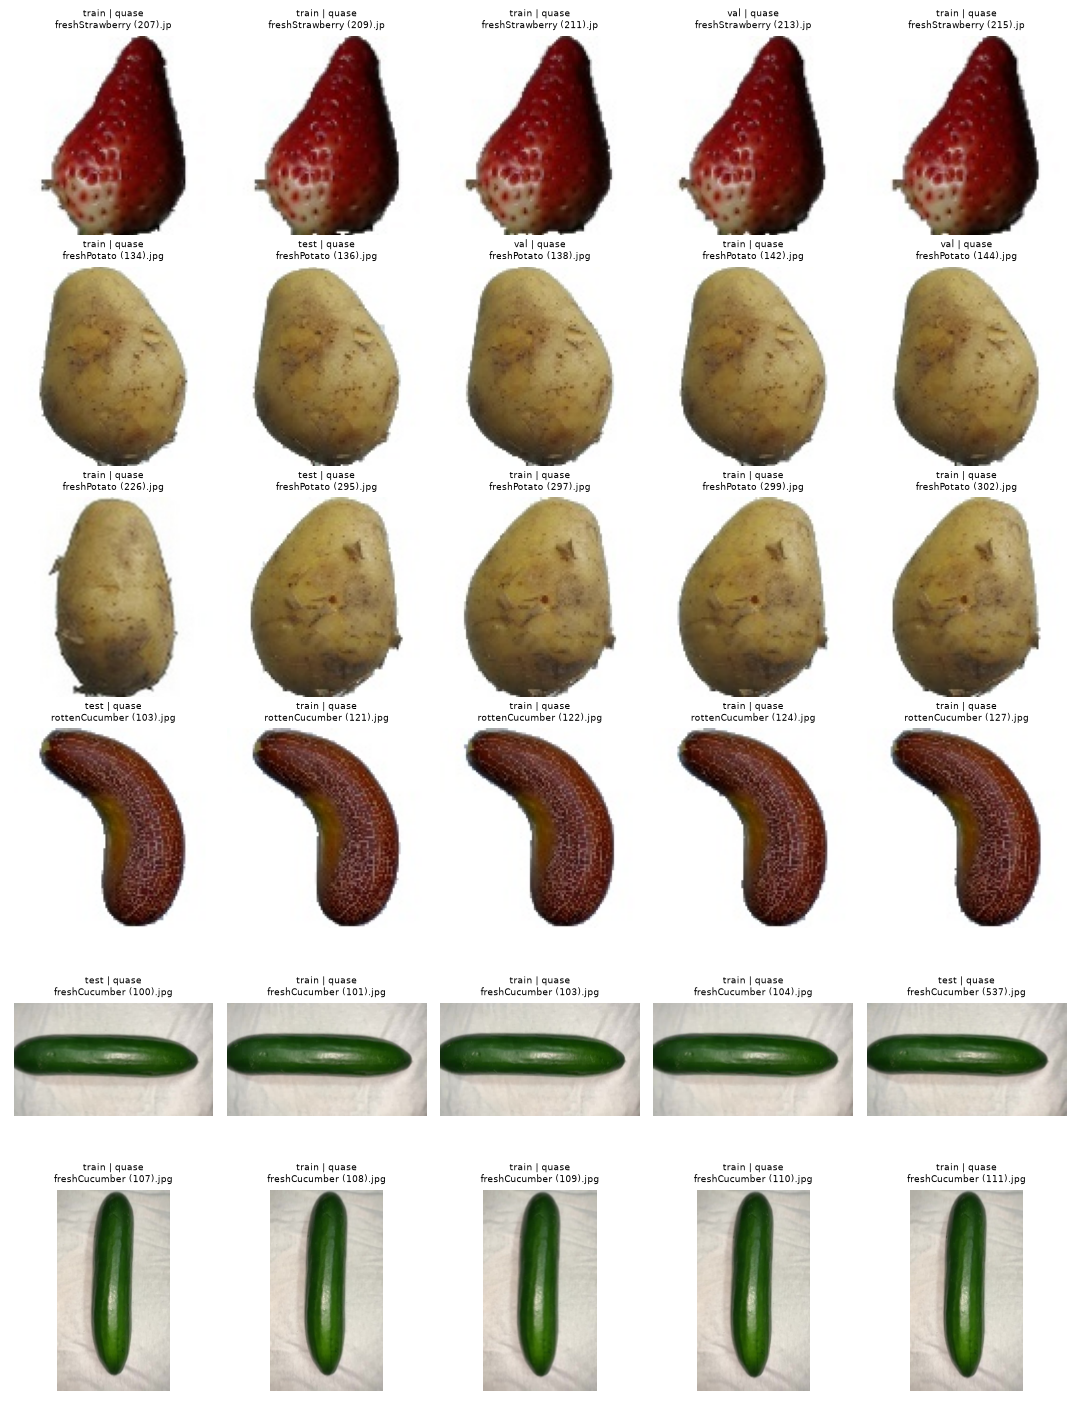

In [6]:
dup.save_preview(root, rows, groups, path=str(ROOT / "duplicates_preview.png"), n_groups=6)
display(Image(str(ROOT / "duplicates_preview.png"), width=900))

Cada linha é um grupo de duplicatas; o título mostra o **split** de cada imagem. Na mesma linha aparecem
`train`, `val` e `test`: é o vazamento que a correção elimina.

### Mesma imagem com rótulos diferentes

Também encontramos imagens idênticas em **classes diferentes**, um erro de rotulação do próprio dataset.
Elas não foram alteradas e ficam registradas como limitação.

Prévia dos pares entre classes salva em /home/tais/Documents/cnn-ciencia-de-dados/duplicates_entre_classes.png


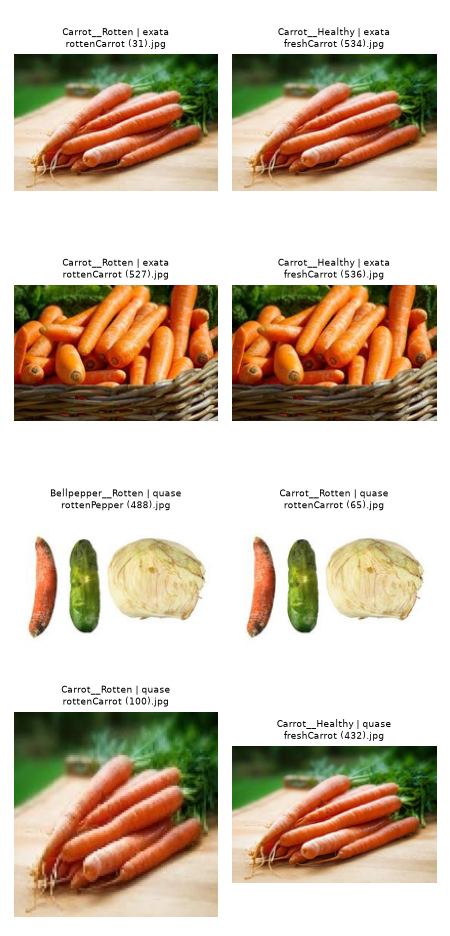

In [7]:
dup.save_cross_class_preview(root, rows, cross_class[:4], path=str(ROOT / "duplicates_entre_classes.png"))
display(Image(str(ROOT / "duplicates_entre_classes.png"), width=450))

**Limitação do método:** frutas pequenas sobre fundo liso (algumas mangas) às vezes são agrupadas mesmo
sendo frutas diferentes. O efeito é apenas mover algumas imagens a mais para o treino, nunca deixar vazamento.

## 4. Normalização

Os pixels são levados de [0, 255] para a escala que o modelo espera. A normalização é uma camada Keras,
aplicada igualmente a treino, validação e teste.

| Opção | Resultado | Para qual modelo |
|---|---|---|
| `"0_1"` (padrão) | pixel / 255 | CNN do zero |
| `"-1_1"` | pixel / 127,5 − 1 | MobileNet, Xception, Inception |
| `"imagenet"` | (pixel − média) / desvio do ImageNet | ResNet, VGG |
| `None` | sem alteração | EfficientNet, ConvNeXt (normalizam por dentro) |

In [8]:
print(f"{'original':10s} min {float(images.numpy().min()):8.2f}  max {float(images.numpy().max()):8.2f}")
for modo in ["0_1", "-1_1", "imagenet"]:
    x = build_normalization(modo)(images).numpy()
    print(f"{modo:10s} min {x.min():8.2f}  max {x.max():8.2f}  média {x.mean():6.2f}")

original   min     0.00  max   255.00
0_1        min     0.00  max     1.00  média   0.56
-1_1       min    -1.00  max     1.00  média   0.11
imagenet   min    -2.12  max     2.64  média   0.47


## 5. Aumento de dados (*data augmentation*)

Aplicado **apenas ao treino**, com transformações sorteadas de novo a cada época. Assim o modelo vê
variações diferentes das mesmas imagens, o que reduz o *overfitting*.

| Transformação | Intensidade |
|---|---|
| Espelhamento horizontal e vertical | aleatório |
| Rotação | até ±36° |
| Zoom | até ±10% |
| Translação | até ±10% |
| Contraste | até ±10% |
| Brilho | até ±10% |

**Matiz e saturação não são alterados**, porque a cor é uma das principais pistas para distinguir um
alimento saudável de um podre. As bordas criadas pela rotação e pela translação são preenchidas por
reflexo da imagem. Validação e teste recebem só a normalização.

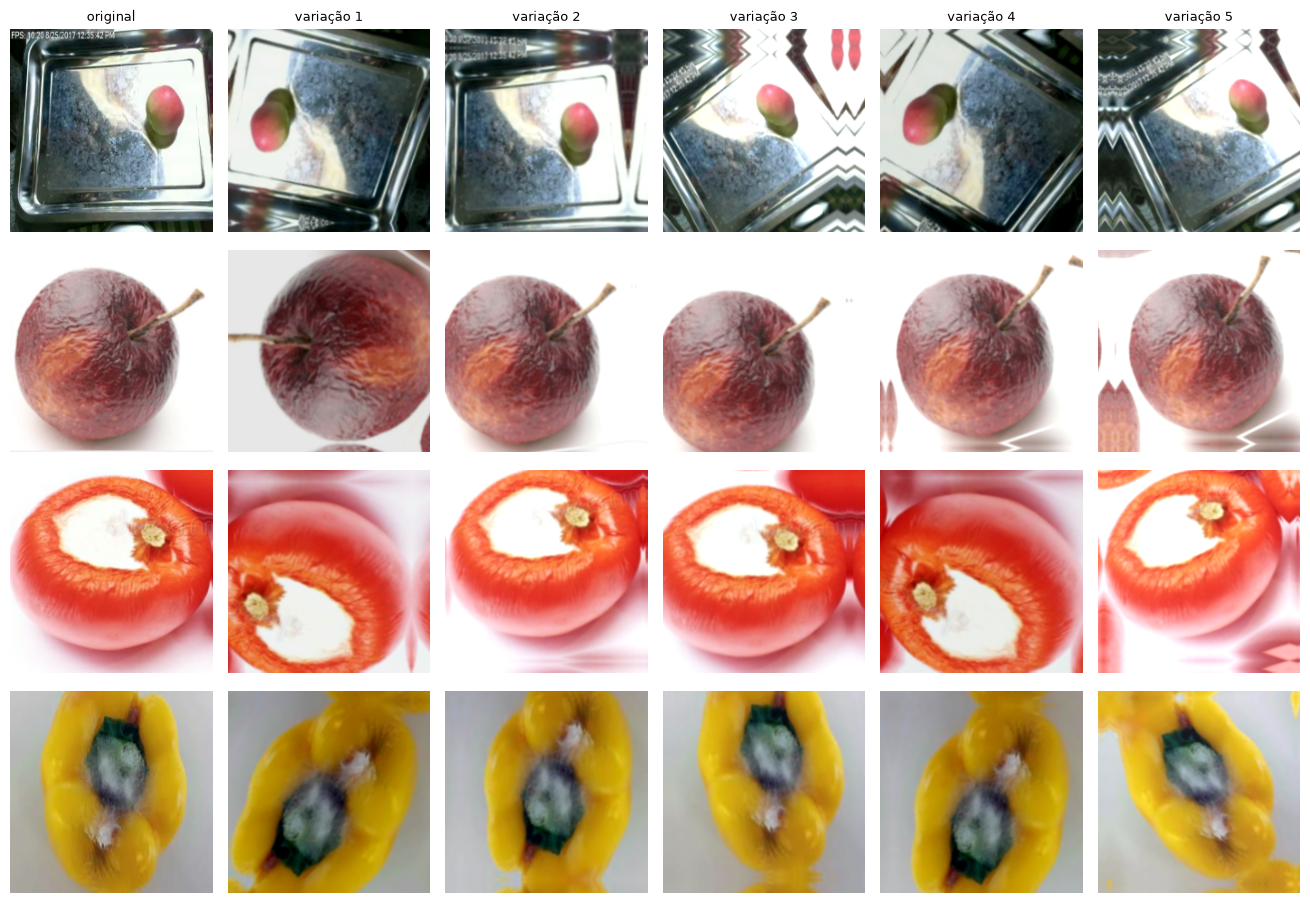

In [9]:
augmentation = build_augmentation()
n_img, n_var = 4, 5
fig, axes = plt.subplots(n_img, n_var + 1, figsize=(2.2 * (n_var + 1), 2.3 * n_img))
for i in range(n_img):
    axes[i, 0].imshow(images[i].numpy().astype("uint8"))
    axes[i, 0].set_title("original" if i == 0 else "", fontsize=9)
    for j in range(1, n_var + 1):
        aug = augmentation(images[i : i + 1], training=True)[0]
        axes[i, j].imshow(np.asarray(aug).clip(0, 255).astype("uint8"))
        if i == 0:
            axes[i, j].set_title(f"variação {j}", fontsize=9)
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout(); plt.show()

## 6. Desbalanceamento: pesos das classes

Para o modelo não ignorar as classes pequenas, cada classe recebe um **peso na função de perda**:

$$w_c = \frac{\text{total de imagens de treino}}{\text{nº de classes} \times \text{imagens de treino da classe } c}$$

Classes pequenas pesam mais, e as grandes, menos. Os pesos vão direto no `model.fit(class_weight=...)`.
Pelo mesmo motivo, a avaliação usa **F1 macro** e métricas por classe, não só a acurácia.

In [10]:
weights = compute_class_weights(class_names)
print(f"{'classe':24s} {'treino':>7s} {'peso':>6s}")
for i in sorted(weights, key=weights.get, reverse=True):
    print(f"{class_names[i]:24s} {treino[class_names[i]]:7d} {weights[i]:6.2f}")

classe                    treino   peso
Grape__Healthy               140   5.23
Grape__Rotten                140   5.23
Guava__Healthy               140   5.23
Guava__Rotten                140   5.23
Jujube__Healthy              140   5.23
Jujube__Rotten               140   5.23
Pomegranate__Healthy         140   5.23
Pomegranate__Rotten          140   5.23
Carrot__Rotten               405   1.81
Potato__Rotten               408   1.79
Bellpepper__Rotten           413   1.77
Cucumber__Rotten             415   1.76
Tomato__Rotten               417   1.75
Tomato__Healthy              422   1.73
Cucumber__Healthy            426   1.72
Bellpepper__Healthy          427   1.71
Potato__Healthy              430   1.70
Carrot__Healthy              433   1.69
Strawberry__Rotten          1118   0.65
Strawberry__Healthy         1123   0.65
Mango__Healthy              1269   0.58
Banana__Healthy             1399   0.52
Orange__Healthy             1453   0.50
Orange__Rotten              1530   0.48


## Resumo

| Etapa | O que foi feito |
|---|---|
| Padronização | RGB, 224×224, arquivos corrompidos descartados |
| Divisão | 70/15/15 estratificada, semente fixa, salva em `data/splits.csv` |
| Duplicatas | MD5 + hash perceptual + cor; grupos inteiros num único split |
| Rótulos conflitantes | identificados e registrados (não alterados) |
| Normalização | [0, 1] (ou a escala do modelo pré-treinado) |
| Augmentation | flip, rotação, zoom, translação, contraste e brilho; só no treino |
| Desbalanceamento | pesos por classe + avaliação com F1 macro |

**Como usar nos modelos:**

```python
from src.data_loader import load_datasets
from src.preprocessing import build_preprocessing, compute_class_weights

train_ds, val_ds, test_ds, class_names = load_datasets()

inputs = keras.Input(shape=(224, 224, 3))
x = build_preprocessing(normalization="0_1")(inputs)   # augmentation + normalização
# ... resto da CNN
model.fit(train_ds, validation_data=val_ds, class_weight=compute_class_weights(class_names))
```